<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AML6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total Missing values: 879
Duplicate rows: 0
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


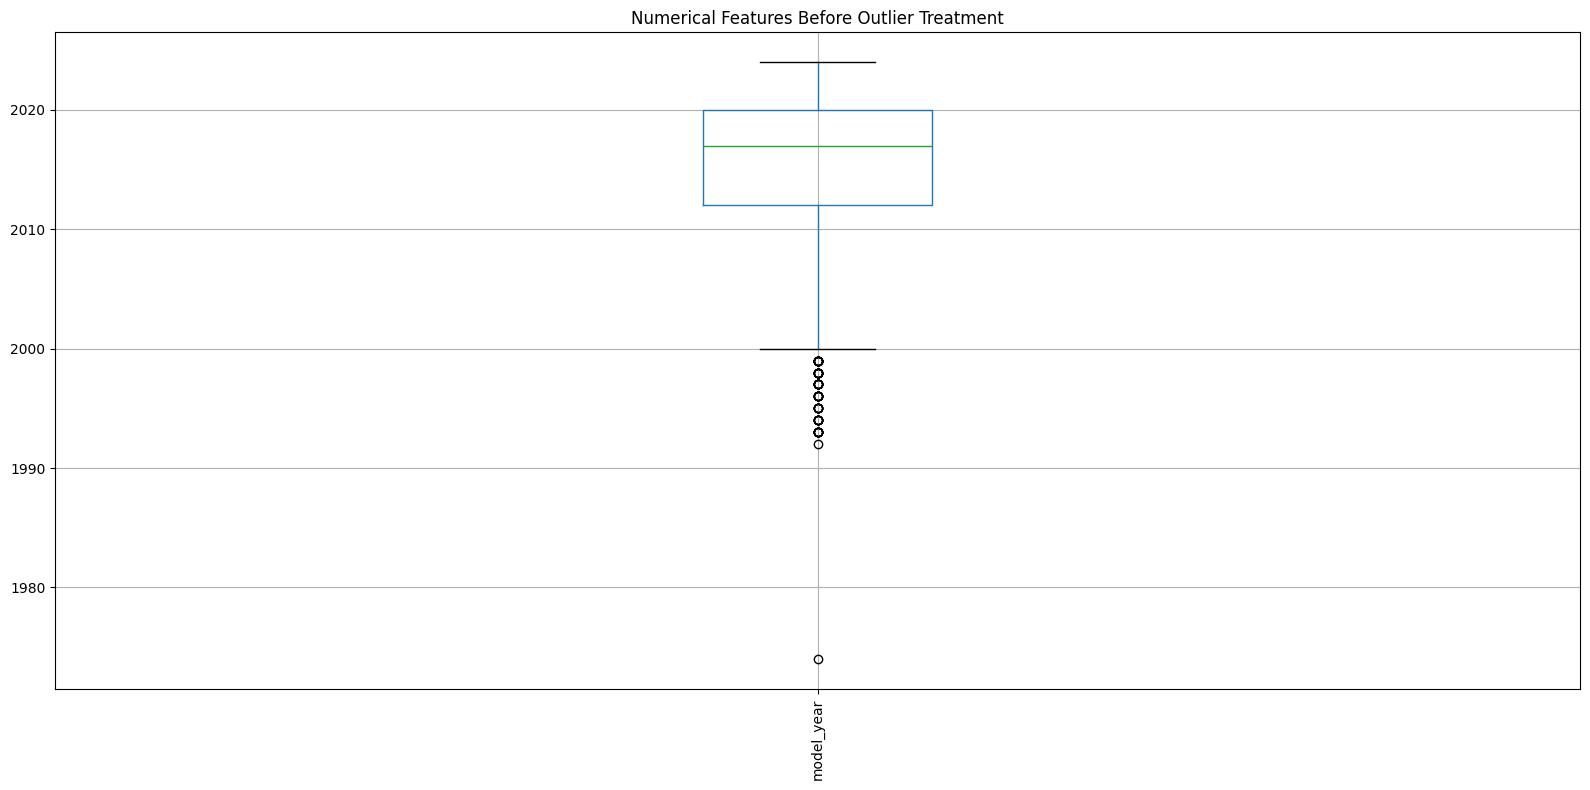

Remaining missing values:
0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

car_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AML/used_cars.csv")
target_car = "price"       # Modify according to the actual dataset
print("Total Missing values:",car_df.isnull().sum().sum())
print("Duplicate rows:", car_df.duplicated().sum())
print(car_df.isnull().sum())

car_df = car_df.drop_duplicates().copy()

numeric_columns = car_df.select_dtypes(include=np.number).columns
categorical_columns = car_df.select_dtypes(
    include=["object", "category"]
).columns

# Fill missing values
for column in numeric_columns:
    car_df[column] = car_df[column].fillna(car_df[column].median())

for column in categorical_columns:
    if car_df[column].isnull().sum()>0:
      car_df[column] = car_df[column].fillna(car_df[column].mode()[0])

# Box plots before outlier treatment
car_df[numeric_columns].boxplot(figsize=(16, 8), rot=90)
plt.title("Numerical Features Before Outlier Treatment")
plt.tight_layout()
plt.show()

# IQR-based outlier capping
for column in numeric_columns:
    q1 = car_df[column].quantile(0.25)
    q3 = car_df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    car_df[column] = car_df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Remaining missing values:")
print(car_df.isnull().sum().sum())

car_df.to_csv("car_price_cleaned.csv", index=False)
